# Preliminary Feasibility Validation: ROS 2 / GP / GRG Reconstruction Experiment

**Purpose:** assess whether an integrated ROS 2 / Gazebo - Nav2 - GP - GRG simulation can support the final study of how MI, EMSE and WIVR scoring affect temperature-field reconstruction. This is preliminary feasibility evidence under simplified, explicitly recorded conditions.

The saved synthetic pilot used a 10 x 8 m scene, three sensing sites, node-arrival observations, a fixed-parameter RBF GP, and fixed WIVR spatial weights. Each policy executed navigation, measurement acquisition, posterior updates, replanning and return, followed by reconstruction evaluation at the same hidden inputs.

**Evidence status:** the original numerical differences and figures are preserved as pilot outputs. They do not establish the final ranking or validate continuous edge sensing, GSTools SRF, Adaptive WIVR, or real-site-scale operation. The revised experiment is specified in [WELL-E 项目核心逻辑](../../Notes/WELL-E项目核心逻辑.md). See README for the executed methods and dependencies.

This documentation revision does not rerun the simulation, retrain the GP, or change saved observations or outputs.

In [1]:
from pathlib import Path
import json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT / 'result').is_dir():
    raise RuntimeError('Run this notebook from Code/ROS_Nav2_policy_compare')
RUN = ROOT / 'result/synthetic_ros_full_01'
def read_json(path): return json.loads(path.read_text())
def rows(path):
    with path.open(newline='', encoding='utf-8-sig') as f: return list(csv.DictReader(f))
evaluation = read_json(RUN / 'evaluation.json')
execution = read_json(RUN / 'execution.json')
bundle_text = execution['bundle'].replace('\\','/')
marker = '/Code/ROS_Nav2_policy_compare/'
BUNDLE = ROOT / bundle_text.split(marker,1)[1] if marker in bundle_text else Path(bundle_text)
summary = rows(RUN / 'summary.csv')
curves = rows(RUN / 'reconstruction_curves.csv')
policies = ['mi','emse','wivr']
colors = {'History Only':'gray','MI':'#3574b9','EMSE':'#d47b22','WIVR':'#2b9975'}
print('Mode:', evaluation['mode'], '| Identical hidden records:', evaluation['hidden_count'])
print('Final real-data comparison completed:', evaluation['full_real_comparison_complete'])
print('Initial historical observations:', len(np.load(RUN/'mi/gp_000.npz')['x']))
print('Physical-unit RBF parameters:', read_json(BUNDLE/'online/parameters.json'))
print('Objective tests:', read_json(ROOT/'result/math_tests.json'))
print('Original-model equivalence:', read_json(ROOT/'result/training_equivalence.json'))
if (ROOT/'result/history_training_validation.json').is_file():
    print('Separate historical-fit preparation check:',read_json(ROOT/'result/history_training_validation.json'))

Mode: synthetic_fixture | Identical hidden records: 1350
Final real-data comparison completed: False
Initial historical observations: 312
Physical-unit RBF parameters: {'lengthscales_m_m_s': [2.5, 2.5, 180.0], 'output_variance_c2': 1.0, 'noise_variance_c2': 0.01, 'mean_c': 20.0}
Objective tests: {'tests': 11, 'failures': 0, 'errors': 0, 'passed': True}
Original-model equivalence: {'passed': True, 'scope': 'synthetic numerical equivalence, not field-model validation', 'maximum_mean_error_c': 3.552713678800501e-15, 'maximum_variance_error_c2': 3.400058012914542e-16, 'reused_source': '/workspace/Code/GP3D_baseline_test/10.16_testing_code/3D_time&spatial temp field rebuild & prediction/gp_model.py', 'time_conversion': 'old hours -> new seconds, lengthscale multiplied by 3600'}
Separate historical-fit preparation check: {'passed': True, 'iterations': 300, 'history_observations': 312, 'runs': ['synthetic-0', 'synthetic-1', 'synthetic-2', 'synthetic-3'], 'checkpoint': 'validation/history_fit_

## Pilot numerical outputs
RMSE and MAE are in °C. These saved numerical outputs document the preliminary experiment, not a final real-field ranking. Distance and mission duration come from physical telemetry and ROS time. Measurement counts include temporal revisits and are not counts of distinct spatial sites. History Only performs no navigation.

In [2]:
columns = [('method','Method'),('rmse_c','RMSE (°C)'),('mae_c','MAE (°C)'),('measurements','Measurements'),
           ('distance_m','Distance (m)'),('duration_s','Duration (s)'),('return_home_success','Home'),('status','Status')]
table = '| ' + ' | '.join(label for key,label in columns) + ' |\n'
table += '| ' + ' | '.join('---' for _ in columns) + ' |\n'
for row in summary:
    values=[]
    for key,label in columns:
        value=row.get(key,'')
        if key in ('rmse_c','mae_c','distance_m','duration_s'): value=f'{float(value):.4f}'
        values.append(str(value) or 'N/A')
    table += '| ' + ' | '.join(values) + ' |\n'
display(Markdown(table))

| Method | RMSE (°C) | MAE (°C) | Measurements | Distance (m) | Duration (s) | Home | Status |
| --- | --- | --- | --- | --- | --- | --- | --- |
| History Only | 0.6674 | 0.6112 | 0 | 0.0000 | 0.0000 | N/A | no_navigation_control |
| MI | 0.2235 | 0.1151 | 68 | 135.4450 | 843.8160 | True | passed |
| EMSE | 0.1637 | 0.0784 | 70 | 135.4437 | 843.6180 | True | passed |
| WIVR | 0.0997 | 0.0467 | 60 | 138.8362 | 844.1740 | True | passed |


## Reconstruction and posterior uncertainty
Curves re-query the same full hidden space-time set after each posterior update. They are retrospective full-interval evaluations, not instantaneous sensor errors or a separately designed forecasting test.

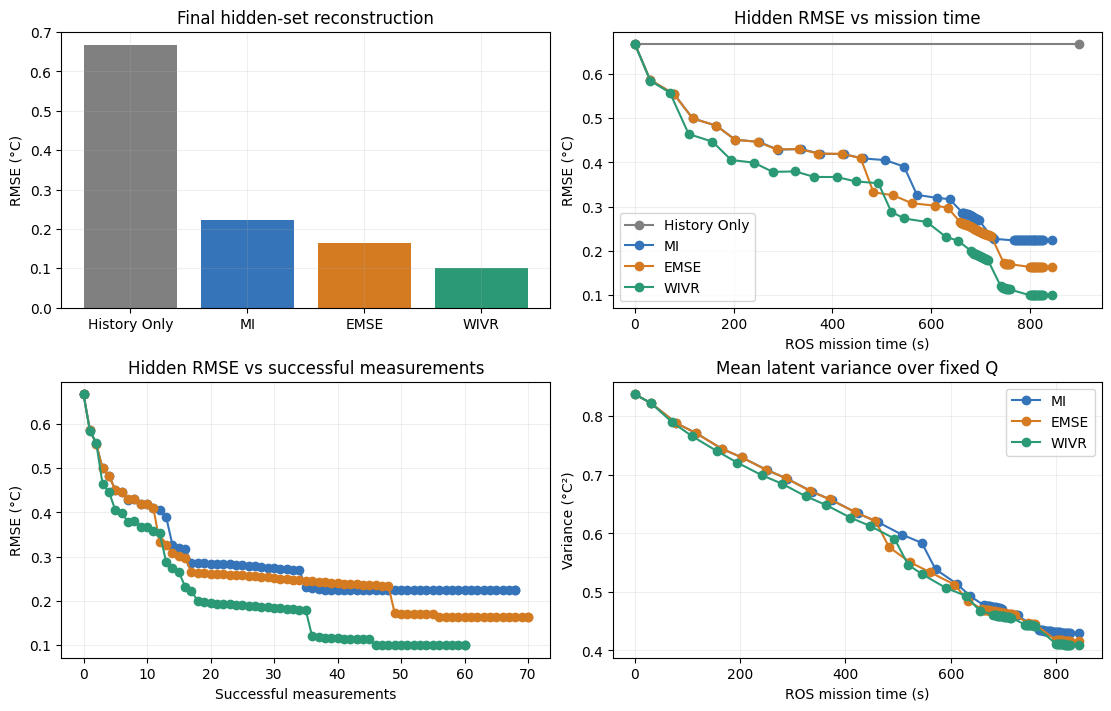

In [3]:
fig,axes=plt.subplots(2,2,figsize=(11,7),constrained_layout=True)
axes[0,0].bar([r['method'] for r in summary],[float(r['rmse_c']) for r in summary],color=[colors[r['method']] for r in summary])
axes[0,0].set(title='Final hidden-set reconstruction',ylabel='RMSE (°C)')
for method in ['History Only','MI','EMSE','WIVR']:
    selected=[r for r in curves if r['method']==method]
    if not selected:continue
    t=[float(r['time_s']) for r in selected];n=[int(r['measurements']) for r in selected];rmse=[float(r['rmse_c']) for r in selected]
    axes[0,1].plot(t,rmse,'o-',label=method,color=colors[method])
    axes[1,0].plot(n,rmse,'o-',label=method,color=colors[method])
    variance=[r for r in selected if r.get('mean_query_variance_c2')]
    if variance:axes[1,1].plot([float(r['time_s']) for r in variance],[float(r['mean_query_variance_c2']) for r in variance],'o-',label=method,color=colors[method])
axes[0,1].set(title='Hidden RMSE vs mission time',xlabel='ROS mission time (s)',ylabel='RMSE (°C)')
axes[1,0].set(title='Hidden RMSE vs successful measurements',xlabel='Successful measurements',ylabel='RMSE (°C)')
axes[1,1].set(title='Mean latent variance over fixed Q',xlabel='ROS mission time (s)',ylabel='Variance (°C²)')
for ax in axes.flat:ax.grid(alpha=.2)
axes[0,1].legend();axes[1,1].legend();plt.show()

## Actual Nav2 trajectories, travel estimates and computation
Paths below are physical Gazebo odometry, not GRG straight-line routes. Travel-time estimates include conservative speed/turn/reserve assumptions and should not be interpreted as calibrated predictions.

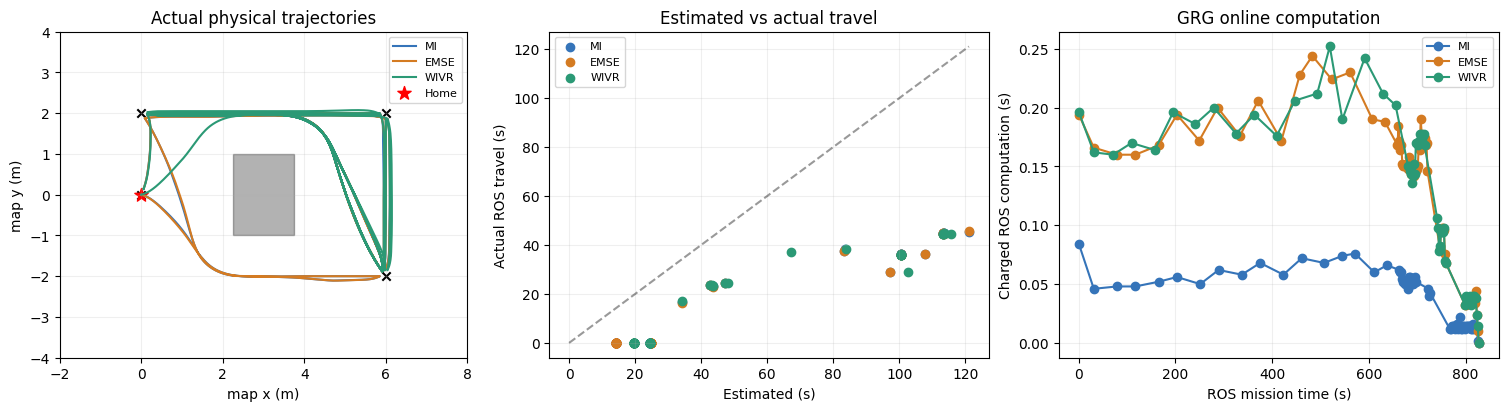

In [4]:
from matplotlib.patches import Rectangle
fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
# Geometry comes from the saved physical world configuration, not a drawn result.
meta=read_json(RUN/'run_configuration.json')
scene=meta['scene'];xmin,xmax,ymin,ymax=scene['map_bounds_m']
if meta['mode']=='synthetic_fixture':
    obstacle=scene['obstacle'];x,y=obstacle['center_m'];w,h=obstacle['size_m']
    axes[0].add_patch(Rectangle((x-w/2,y-h/2),w,h,color='black',alpha=.3))
else:
    import matplotlib.image as mpimg
    import yaml
    mapmeta=yaml.safe_load((RUN/'mi/generated/map.yaml').read_text())
    image=mpimg.imread(RUN/'mi/generated'/mapmeta['image']);ox,oy,_=mapmeta['origin'];res=mapmeta['resolution']
    axes[0].imshow(image,cmap='gray',extent=[ox,ox+image.shape[1]*res,oy,oy+image.shape[0]*res])
all_est=[];all_actual=[]
for policy in policies:
    trajectory=rows(RUN/policy/'trajectory.csv');navigation=rows(RUN/policy/'navigation.csv');plans=read_json(RUN/policy/'plans.json')
    axes[0].plot([float(r['x_m']) for r in trajectory],[float(r['y_m']) for r in trajectory],label=policy.upper(),color=colors[policy.upper()])
    valid=[r for r in navigation if r.get('estimated_s') and r.get('actual_travel_s')]
    est=[float(r['estimated_s']) for r in valid];actual=[float(r['actual_travel_s']) for r in valid]
    axes[1].scatter(est,actual,label=policy.upper(),color=colors[policy.upper()]);all_est+=est;all_actual+=actual
    axes[2].plot([p['time_s'] for p in plans],[p['ros_compute_s'] for p in plans],'o-',label=policy.upper(),color=colors[policy.upper()])
points=np.array(meta['candidate_xy_m']);axes[0].scatter(points[:,0],points[:,1],marker='x',c='black');axes[0].scatter(*points[0],marker='*',s=100,c='red',label='Home')
axes[0].set(xlim=(xmin,xmax),ylim=(ymin,ymax),aspect='equal',title='Actual physical trajectories',xlabel='map x (m)',ylabel='map y (m)')
bound=max(all_est+all_actual+[1]);axes[1].plot([0,bound],[0,bound],'k--',alpha=.4)
axes[1].set(title='Estimated vs actual travel',xlabel='Estimated (s)',ylabel='Actual ROS travel (s)')
axes[2].set(title='GRG online computation',xlabel='ROS mission time (s)',ylabel='Charged ROS computation (s)')
for ax in axes:ax.grid(alpha=.2);ax.legend(fontsize=8)
plt.show()

## Trace, acceptance and conclusions
An example traces the first MI route, actual Nav2 arrival, original recorded measurement and posterior update. All assertions use saved outputs.

In [5]:
for policy in policies:
    mission=read_json(RUN/policy/'mission.json');bag=read_json(RUN/policy/'rosbag_summary.json')
    acquired=rows(RUN/policy/'measurements.csv');sites=sorted({int(r['node']) for r in acquired})
    print(policy.upper(),':',mission['successful_measurements'],'updates at',len(sites),'distinct sensing sites,',round(mission['duration_s'],3),'s, Home=',mission['return_home_success'],
          '| rosbag:',bag['status'],'| clearance:',bag.get('minimum_footprint_clearance_m'))
    assert mission['status']=='passed' and mission['return_home_success'] and mission['within_budget']
    assert mission['successful_measurements']>=2 and mission['planning_decisions']>=2
    assert bag['status']=='passed'
trace=[json.loads(line) for line in (RUN/'mi/events.jsonl').read_text().splitlines()]
for event in ['grg_plan','navigation_result','gp_update']:
    print(event,':',next(r for r in trace if r['event']==event))
print('Replan after first posterior update:',next(r for r in trace if r['event']=='grg_plan' and r['gp_version']==1))
# Recompute the logged first-route MI from saved initial observations and
# scheduled event inputs, without future temperature values.
import sys
sys.path.insert(0,str(ROOT/'testing_code'))
from nav2_policy.gp import GaussianProcess
initial=np.load(RUN/'mi/gp_000.npz');hp=read_json(BUNDLE/'online/parameters.json')
initial_gp=GaussianProcess(initial['x'],initial['y'],hp)
first=read_json(RUN/'mi/plans.json')[0];points=read_json(RUN/'run_configuration.json')['candidate_xy_m']
events=np.array([[*points[node],t] for node,t in zip(first['route'][1:-1],first['arrivals_s'])])
covariance=initial_gp.covariance(events)
reproduced_mi=.5*np.linalg.slogdet(np.eye(len(events))+covariance/initial_gp.noise)[1]
print('First planned sensing events (m,m,s):',events)
print('Conditional event covariance (°C²):',covariance)
print('Recomputed MI / logged MI (nats):',reproduced_mi,first['score'])
assert np.isclose(reproduced_mi,first['score'],atol=1e-10,rtol=1e-10)
print('Hidden records and common inputs audit:',read_json(RUN/'fairness.json'))
baseline=float(next(r['rmse_c'] for r in summary if r['method']=='History Only'))
print('Observed fixture RMSE differences from History Only (positive = lower RMSE):')
for row in summary[1:]:print(row['method'],round(baseline-float(row['rmse_c']),6),'°C')
display(Markdown('**Conclusion:** '+evaluation['note']+' Numerical differences describe this recorded fixture only. '
    'They do not establish the best policy for the real field. The formal comparison requires five registered real datasets and the matching 2D navigation map.'))

MI : 68 updates at 3 distinct sensing sites, 843.816 s, Home= True | rosbag: passed | clearance: 0.5736585081449304
EMSE : 70 updates at 3 distinct sensing sites, 843.618 s, Home= True | rosbag: passed | clearance: 0.5814252090511576
WIVR : 60 updates at 3 distinct sensing sites, 844.174 s, Home= True | rosbag: passed | clearance: 0.5735830253980548
grg_plan : {'event': 'grg_plan', 'index': 0, 'time_s': 0.3740000000000001, 'finish_compute_s': 0.45799999999999996, 'route': [4, 3, 1, 2, 0], 'arrivals_s': [98.0, 212.0, 262.0], 'planned_finish_s': 343.1056238608511, 'score': 6.361281956084836, 'policy': 'mi', 'wall_compute_s': 0.08233491999999387, 'ros_compute_s': 0.08399999999999985, 'evaluations': 25, 'gp_version': 0, 'objective_calls': 22, 'objective_cache_hits': 3}
navigation_result : {'event': 'navigation_result', 'index': 0, 'node': 3, 'phase': 'sensing', 'start_s': 0.45999999999999996, 'finish_s': 29.566000000000003, 'estimated_s': 97.21892444820926, 'planned_length_m': None, 'succe

**Conclusion:** SYNTHETIC 900-second-budget Nav2 comparison; no acquisition cap; NOT a real-field result. Numerical differences describe this recorded fixture only. They do not establish the best policy for the real field. The formal comparison requires five registered real datasets and the matching 2D navigation map.

## Interpretation for the final experiment

The saved results provide initial evidence that the complete ROS - GP - GRG simulation can execute the intended experiment workflow and support a traceable, common-input reconstruction evaluation for three scoring policies. The pilot genuinely evaluated reconstruction differences; those values remain limited to the executed fixture.

Use this result as a preliminary feasibility study for the final experiment. Subsequent readiness checks should verify the added SRF source, continuous sampling/path events, batch updates and Adaptive WIVR, then demonstrate each policy separately. Formal performance conclusions require the revised protocol, registered field map/data and target-scale validation.

The preceding saved console conclusion describes the recorded-data pilot and its legacy five-dataset preparation mode. The current final design uses SRF observations and reserves Dataset 4 for independent interpolation-valid real-data validation when suitable support exists. Historical outputs are retained unchanged.